# Deep Retention — Entrenamiento y evaluación del MLP

Este notebook consume exclusivamente los artefactos generados por el
notebook 02. Entrena una sola red, decide la corrección probabilística con
validación y utiliza test una única vez al final. No lee el CSV original ni
reconstruye el preprocesador.


## 1. Estrategia

Se mantiene `class_weight="balanced"` para atender el desbalance sin
duplicar observaciones. Como la ponderación altera el prior efectivo durante
el entrenamiento, la salida Sigmoid no se considera calibrada por defecto.
Se evaluará en validación una única corrección analítica por pesos de clase:

\[
p_{ajustada}=
rac{p}{p+(w_1/w_0)(1-p)}
\]

Solo se exportará si mejora simultáneamente Brier Score y Log Loss en
validación. No se ajustará ninguna decisión con el conjunto de prueba.


In [1]:
import json
import os
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

PROJECT_ROOT = next(
    candidate
    for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "data" / "Customer-Churn-Records.csv").is_file()
)
ARTIFACT_ROOT = PROJECT_ROOT
EXPORT_ARTIFACTS = True
PROCESSED_DIR = ARTIFACT_ROOT / "data" / "processed"
MODELS_DIR = ARTIFACT_ROOT / "models"


## 2. Carga y compatibilidad de las particiones


In [2]:
required_paths = [
    PROCESSED_DIR / "train.npz",
    PROCESSED_DIR / "validation.npz",
    PROCESSED_DIR / "test.npz",
    PROCESSED_DIR / "metadata.json",
]
missing = [path.name for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Ejecute primero el notebook 02. Faltan: " + ", ".join(missing)
    )

with (PROCESSED_DIR / "metadata.json").open(encoding="utf-8") as file:
    metadata = json.load(file)
with np.load(PROCESSED_DIR / "train.npz", allow_pickle=False) as artifact:
    X_train = artifact["X"].astype(np.float32)
    y_train = artifact["y"].astype(np.int8)
    train_ids = artifact["customer_ids"].astype(np.int64)
    train_artifact_id = str(artifact["artifact_id"].item())
with np.load(PROCESSED_DIR / "validation.npz", allow_pickle=False) as artifact:
    X_validation = artifact["X"].astype(np.float32)
    y_validation = artifact["y"].astype(np.int8)
    validation_ids = artifact["customer_ids"].astype(np.int64)
    validation_artifact_id = str(artifact["artifact_id"].item())
with np.load(PROCESSED_DIR / "test.npz", allow_pickle=False) as artifact:
    test_ids = artifact["customer_ids"].astype(np.int64)
    test_artifact_id = str(artifact["artifact_id"].item())

artifact_id = metadata["artifact_id"]
identifiers_match = {
    train_artifact_id, validation_artifact_id, test_artifact_id
} == {artifact_id}
no_overlap = not (
    set(train_ids) & set(validation_ids)
    or set(train_ids) & set(test_ids)
    or set(validation_ids) & set(test_ids)
)
dimensions_match = (
    X_train.shape[1] == X_validation.shape[1]
    == len(metadata["transformed_features"])
)
checks = pd.Series(
    {
        "artifact_id común": identifiers_match,
        "particiones sin solapamiento": no_overlap,
        "dimensiones compatibles": dimensions_match,
        "matrices finitas": bool(
            np.isfinite(X_train).all() and np.isfinite(X_validation).all()
        ),
        "Complain excluida": "Complain" not in metadata["features"],
    },
    name="resultado",
)
display(checks.to_frame())
if not checks.all():
    raise ValueError("Los artefactos de preprocesamiento son incompatibles.")
print("Test permanece reservado: solo se cargaron sus identificadores.")


,resultado
artifact_id común,True
particiones sin solapamiento,True
dimensiones compatibles,True
matrices finitas,True
Complain excluida,True


Test permanece reservado: solo se cargaron sus identificadores.


## 3. Tratamiento del desbalance


In [3]:
classes = np.array([0, 1], dtype=int)
balanced_weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train.astype(int)
)
class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, balanced_weights)
}
display(
    pd.DataFrame(
        {
            "clase": classes,
            "clientes_train": [int((y_train == label).sum()) for label in classes],
            "peso": [class_weights[int(label)] for label in classes],
        }
    )
)


,clase,clientes_train,peso
0,0,5573,0.628028
1,1,1427,2.452698


## 4. Arquitectura, compilación y entrenamiento


In [4]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(X_train.shape[1],), name="input"),
        tf.keras.layers.Dense(128, activation="relu", name="dense_128"),
        tf.keras.layers.BatchNormalization(name="batch_normalization"),
        tf.keras.layers.Dropout(0.25, name="dropout_025"),
        tf.keras.layers.Dense(64, activation="relu", name="dense_64"),
        tf.keras.layers.Dropout(0.15, name="dropout_015"),
        tf.keras.layers.Dense(1, activation="sigmoid", name="probability"),
    ],
    name="deep_retention_mlp",
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
)
model.summary()


Model: "deep_retention_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_128 (Dense)               │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_025 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_015 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,369 (40.50 KB)

 Trainable params: 10,113 (39.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [5]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=100,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=0,
)
history_df = pd.DataFrame(history.history)
best_epoch = int(history_df["val_loss"].idxmin() + 1)
print(f"Épocas ejecutadas: {len(history_df)}")
print(f"Mejor época según val_loss: {best_epoch}")
display(history_df.iloc[[best_epoch - 1]])


Épocas ejecutadas: 22
Mejor época según val_loss: 10


,accuracy,loss,pr_auc,roc_auc,val_accuracy,val_loss,val_pr_auc,val_roc_auc
9,0.779571,0.474988,0.659379,0.853261,0.772667,0.466119,0.690657,0.854545


## 5. Curvas de aprendizaje


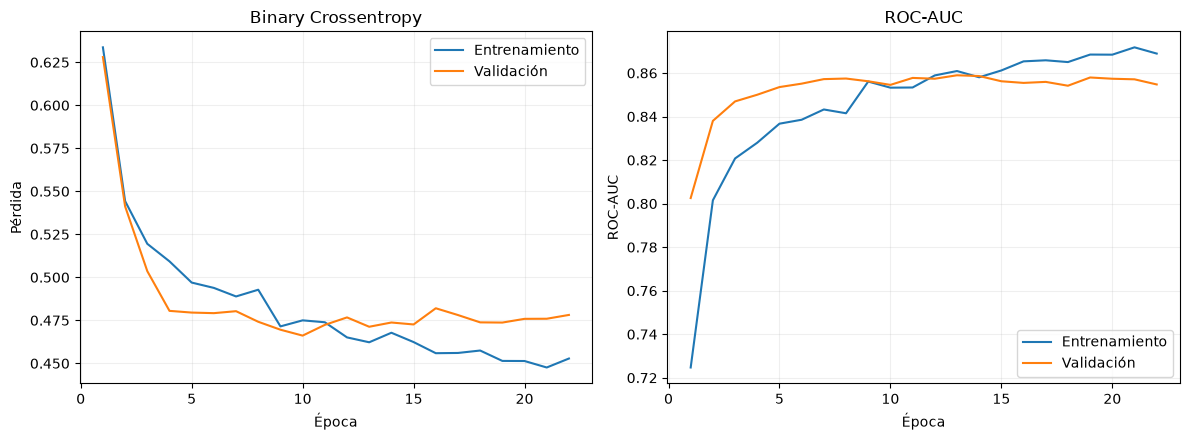

In [6]:
epochs_axis = np.arange(1, len(history_df) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(epochs_axis, history_df["loss"], label="Entrenamiento")
axes[0].plot(epochs_axis, history_df["val_loss"], label="Validación")
axes[0].set(title="Binary Crossentropy", xlabel="Época", ylabel="Pérdida")
axes[0].legend()
axes[1].plot(epochs_axis, history_df["roc_auc"], label="Entrenamiento")
axes[1].plot(epochs_axis, history_df["val_roc_auc"], label="Validación")
axes[1].set(title="ROC-AUC", xlabel="Época", ylabel="ROC-AUC")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 6. Evaluación y corrección probabilística en validación


In [7]:
validation_raw = model.predict(X_validation, batch_size=256, verbose=0).reshape(-1)
weight_0 = class_weights[0]
weight_1 = class_weights[1]
validation_adjusted = validation_raw / (
    validation_raw + (weight_1 / weight_0) * (1.0 - validation_raw)
)

def probability_metrics(labels, probabilities):
    return {
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "PR-AUC": average_precision_score(labels, probabilities),
        "Brier Score": brier_score_loss(labels, probabilities),
        "Log Loss": log_loss(labels, probabilities),
    }

validation_comparison = pd.DataFrame(
    {
        "Original": probability_metrics(y_validation, validation_raw),
        "Corregida": probability_metrics(y_validation, validation_adjusted),
    }
).T
display(validation_comparison)

correction_justified = bool(
    validation_comparison.loc["Corregida", "Brier Score"]
    < validation_comparison.loc["Original", "Brier Score"]
    and validation_comparison.loc["Corregida", "Log Loss"]
    < validation_comparison.loc["Original", "Log Loss"]
)
print("Corrección justificada por validación:", correction_justified)
if not correction_justified:
    raise RuntimeError(
        "La corrección compatible con el predictor no mejora la calibración; "
        "se requiere revisar src/prediction.py antes de exportar."
    )


,ROC-AUC,PR-AUC,Brier Score,Log Loss
Original,0.854542,0.69139,0.153208,0.466119
Corregida,0.854542,0.69139,0.105419,0.343671


Corrección justificada por validación: True


,validación_umbral_0.5
Precision,0.732673
Recall,0.483660
F1,0.582677


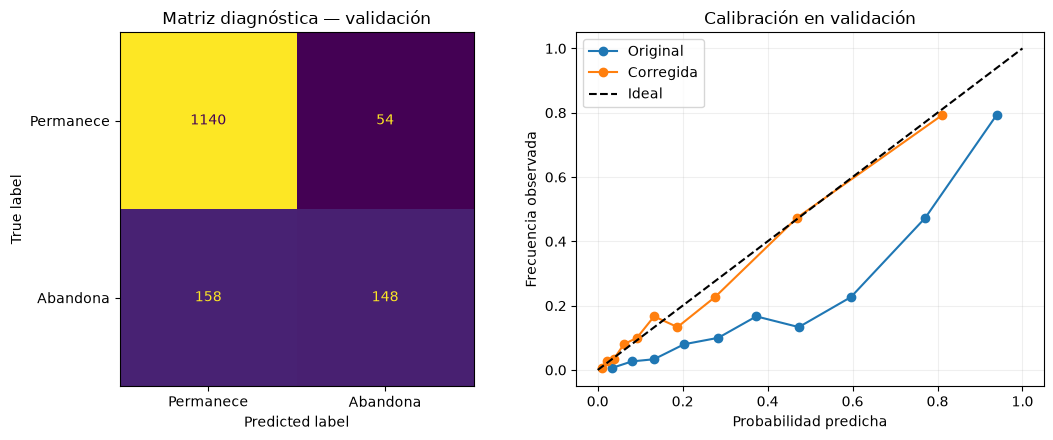

In [8]:
validation_predictions = (validation_adjusted >= 0.5).astype(np.int8)
diagnostic_metrics = pd.Series(
    {
        "Precision": precision_score(y_validation, validation_predictions, zero_division=0),
        "Recall": recall_score(y_validation, validation_predictions, zero_division=0),
        "F1": f1_score(y_validation, validation_predictions, zero_division=0),
    },
    name="validación_umbral_0.5",
)
display(diagnostic_metrics.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_validation, validation_predictions),
    display_labels=["Permanece", "Abandona"],
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Matriz diagnóstica — validación")

for probabilities, label in [
    (validation_raw, "Original"),
    (validation_adjusted, "Corregida"),
]:
    observed, predicted = calibration_curve(
        y_validation, probabilities, n_bins=10, strategy="quantile"
    )
    axes[1].plot(predicted, observed, marker="o", label=label)
axes[1].plot([0, 1], [0, 1], "k--", label="Ideal")
axes[1].set(
    title="Calibración en validación",
    xlabel="Probabilidad predicha",
    ylabel="Frecuencia observada",
)
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


El umbral 0,5 se utiliza únicamente para describir precisión, recall, F1 y
la matriz de confusión. No constituye una regla financiera. La corrección
elegida es monótona: no cambia ROC-AUC ni PR-AUC, pero puede mejorar la
interpretación probabilística medida mediante Brier y Log Loss.


## 7. Exportación compatible


In [9]:
correction_configuration = {
    "method": "class_weight_prior_correction",
    "class_weight_0": weight_0,
    "class_weight_1": weight_1,
    "artifact_id": artifact_id,
    "features": metadata["transformed_features"],
    "validation": {
        "raw_brier": float(validation_comparison.loc["Original", "Brier Score"]),
        "adjusted_brier": float(validation_comparison.loc["Corregida", "Brier Score"]),
        "raw_log_loss": float(validation_comparison.loc["Original", "Log Loss"]),
        "adjusted_log_loss": float(validation_comparison.loc["Corregida", "Log Loss"]),
    },
}

if EXPORT_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    model.save(MODELS_DIR / "modelo_churn.keras")
    with (MODELS_DIR / "correccion_probabilidades.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(correction_configuration, file, ensure_ascii=False, indent=2)
    print("Modelo y corrección exportados de forma controlada.")
else:
    print("Exportación desactivada: los modelos versionados no se modificaron.")


Modelo y corrección exportados de forma controlada.


## 8. Evaluación final única en test


,test_final
ROC-AUC,0.886851
PR-AUC,0.732324
Brier Score,0.095979
Log Loss,0.315112
Precision@0.5,0.782383
Recall@0.5,0.495082
F1@0.5,0.606426


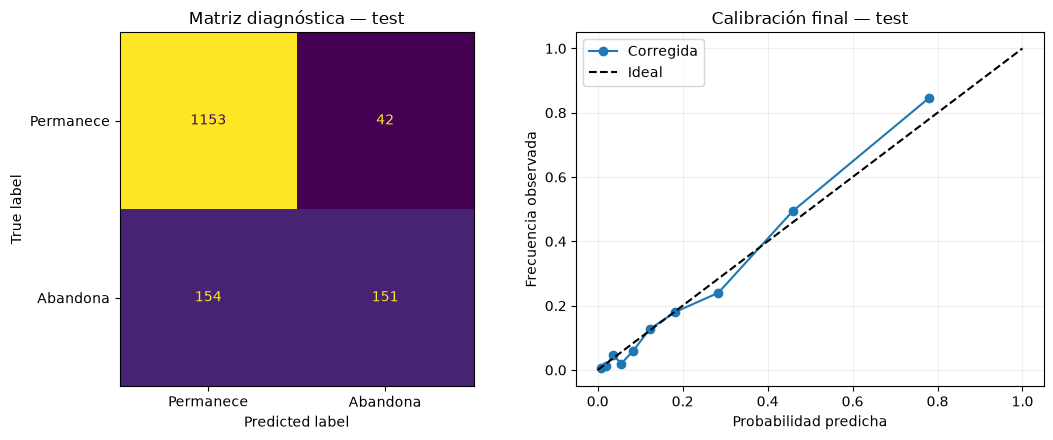

In [10]:
with np.load(PROCESSED_DIR / "test.npz", allow_pickle=False) as artifact:
    X_test = artifact["X"].astype(np.float32)
    y_test = artifact["y"].astype(np.int8)
if not np.isfinite(X_test).all():
    raise ValueError("Test contiene valores no finitos.")

test_raw = model.predict(X_test, batch_size=256, verbose=0).reshape(-1)
test_adjusted = test_raw / (
    test_raw + (weight_1 / weight_0) * (1.0 - test_raw)
)
test_predictions = (test_adjusted >= 0.5).astype(np.int8)
test_metrics = probability_metrics(y_test, test_adjusted)
test_metrics.update(
    {
        "Precision@0.5": precision_score(y_test, test_predictions, zero_division=0),
        "Recall@0.5": recall_score(y_test, test_predictions, zero_division=0),
        "F1@0.5": f1_score(y_test, test_predictions, zero_division=0),
    }
)
display(pd.Series(test_metrics, name="test_final").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_predictions),
    display_labels=["Permanece", "Abandona"],
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Matriz diagnóstica — test")
observed, predicted = calibration_curve(
    y_test, test_adjusted, n_bins=10, strategy="quantile"
)
axes[1].plot(predicted, observed, marker="o", label="Corregida")
axes[1].plot([0, 1], [0, 1], "k--", label="Ideal")
axes[1].set(
    title="Calibración final — test",
    xlabel="Probabilidad predicha",
    ylabel="Frecuencia observada",
)
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 9. Conclusiones

- Se entrenó una única arquitectura MLP con ponderación calculada solo sobre
  entrenamiento y Early Stopping basado en validación.
- `Complain` no forma parte de las características de entrada.
- La corrección por prior se seleccionó porque mejoró Brier Score y Log Loss
  en validación y conserva el contrato actual de inferencia.
- El conjunto de prueba se utilizó una sola vez, después de cerrar el modelo
  y la estrategia probabilística.
- Las probabilidades apoyan el análisis posterior; el umbral diagnóstico de
  0,5 no sustituye la evaluación de rentabilidad ni la GNE.
